# Project Goal

The objective of this exploratory data analysis is to understand the characteristics of the AI4I 2020 Predictive Maintenance Dataset and identify important patterns that influence machine failure.

The insights from this EDA will guide feature engineering, data preprocessing and model selection for the classification task.

# Data Dictionary

| Feature  | Meaning | Unit
| ---------| --------| -----
| UDI	   | ID	     |Integer
| Product ID |	ID	 | Categorical	
| Type	| Feature	| Categorical		
| Air temperature	| Feature	| Continuous	
| Process temperature |	Feature |	Continuous		
| Rotational speed	| Feature	| Integer		
| Torque	| Feature	| Continuous		
| Tool wear	| Feature	| Integer		
| Machine failure	| Target	| Integer	
| TWF	| Target	| Integer	
| HDF	| Target	| Integer
| PWF	| Target	| Integer	
| OSF	| Target	| Integer	
| RNF	| Target	| Integer


In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown

from pathlib import Path
import sys


sys.path.append(str(Path.cwd().parent))

from src.data.make_dataset import load_data, get_data_overview, check_data, validate_data, save_cleand_data
from src.visualization.visualize import plot_mul_histogram, plot_bar


sys.path.append("..")

# -----------------------------
# Global styling
# -----------------------------
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

palette = sns.color_palette("Set2") # Custom palette

%load_ext autoreload
%autoreload 2

# 1. Data Overview
## 1.1 Load Data

In [2]:
df = load_data()
if df is not None:
    print(f"Loaded data:\n{df.head(3)}")
else:
    print(f"Data could not be loaded.")

Loaded data:
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0    0    0    0  


## 1.2 Data Structure

In [3]:
if df is not None:
    rows, columns = get_data_overview(df)
   
    print(f"Data set has {rows} rows and {columns} columns.")

Data set has 10000 rows and 14 columns.


# 2. Data Validation
## 2.1 Basic Overview

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

## 2.2 Checking Missing Value and Duplicate Value

In [5]:
missing_value_msg, duplicated_rows_msg = check_data(df)
print(missing_value_msg)
print(duplicated_rows_msg)

There is no missing value in all columns.
No duplicated rows found in dataset.


## 2.3 Validating

In [6]:
col_num_unique_list, col_cat_unique_list = validate_data(df)

### 2.3.1 Validating Possible Unique Value and its Range in Numeric Variable

In [7]:
for col in col_num_unique_list:
    print(f"Numbers of unique '{col['column']}' value: {col['Total_Unique_Value']}, Range:{col['Max']} - {col['Min']}")

Numbers of unique 'UDI' value: 10000, Range:10000 - 1
Numbers of unique 'Air temperature [K]' value: 93, Range:304.5 - 295.3
Numbers of unique 'Process temperature [K]' value: 82, Range:313.8 - 305.7
Numbers of unique 'Rotational speed [rpm]' value: 941, Range:2886 - 1168
Numbers of unique 'Torque [Nm]' value: 577, Range:76.6 - 3.8
Numbers of unique 'Tool wear [min]' value: 246, Range:253 - 0
Numbers of unique 'Machine failure' value: 2, Range:1 - 0
Numbers of unique 'TWF' value: 2, Range:1 - 0
Numbers of unique 'HDF' value: 2, Range:1 - 0
Numbers of unique 'PWF' value: 2, Range:1 - 0
Numbers of unique 'OSF' value: 2, Range:1 - 0
Numbers of unique 'RNF' value: 2, Range:1 - 0


### 2.3.2 Validating Possible Unique Value in Object Type Variable

In [8]:
for col in col_cat_unique_list:
  print(f"Numbers of unique '{col['column']}' value: {col['Total_Unique_Value']} , Unique category list:{col['Unique_Cat_List']}")

Numbers of unique 'Product ID' value: 10000 , Unique category list:<ArrowStringArray>
['M14860', 'L47181', 'L47182', 'L47183', 'L47184', 'M14865', 'L47186',
 'L47187', 'M14868', 'M14869',
 ...
 'L57170', 'M24851', 'L57172', 'L57173', 'L57174', 'M24855', 'H39410',
 'M24857', 'H39412', 'M24859']
Length: 10000, dtype: str
Numbers of unique 'Type' value: 3 , Unique category list:<ArrowStringArray>
['M', 'L', 'H']
Length: 3, dtype: str


# 3. Exploratory Analysis
## 3.1 Statistical Summary

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


The descriptive statistic telling us data distribution lead to skewness in some column, so histogram chart is plotted to view the distribution of these variable.

## 3.2 Data Distribution

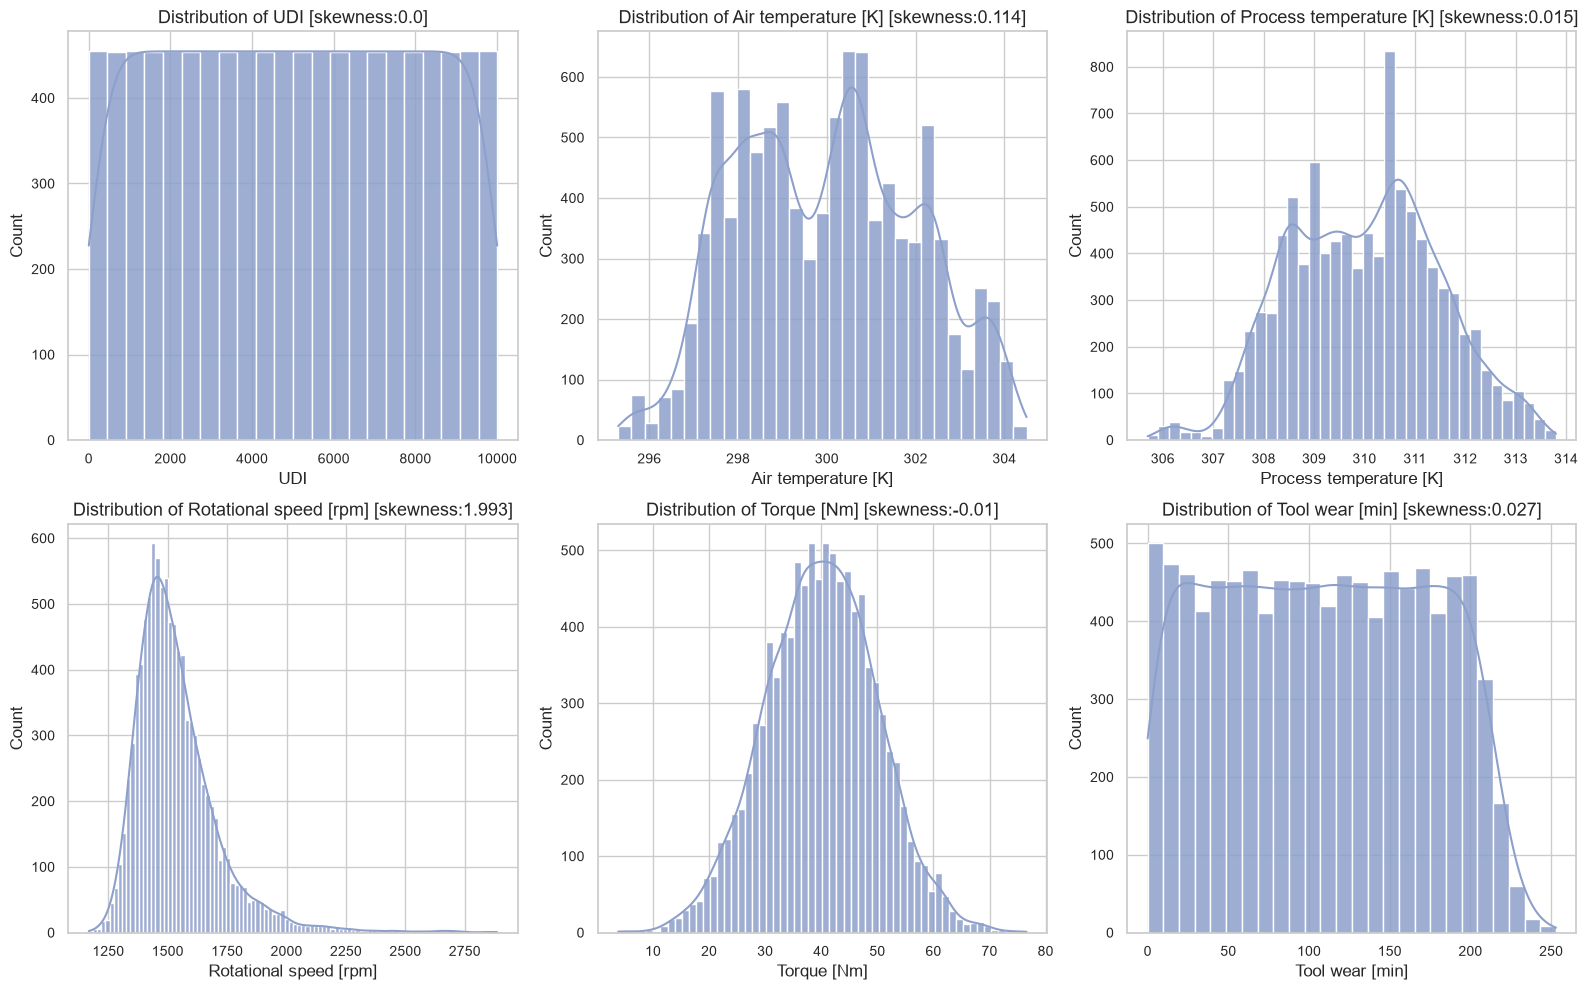

In [10]:
failure = ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

num_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
# Remove UDI and target variables
num_cols = [n for n in num_cols if n != 'UID' and n not in failure ]
cat_cols = df.select_dtypes(include=['object','str']).columns.tolist()

plt.figure(figsize=(16, 10))

plot_mul_histogram(num_cols,df,2)



## 3.3 Detecting Outliers

From the plot above, it is obvious that data are highly right-skewed in column 'Rotational speed [rpm]', which required to handle the outliers and calculate the Interquartile Range (IQR) for those columns.
Therefore, the upper and lower boundaries are calculated to manage these outliers effectively.


                 variable  outlier_ratio  lower_bound  upper_bound
0  Rotational speed [rpm]           4.18       1139.5       1895.5
1             Torque [Nm]           0.69         12.8         67.2


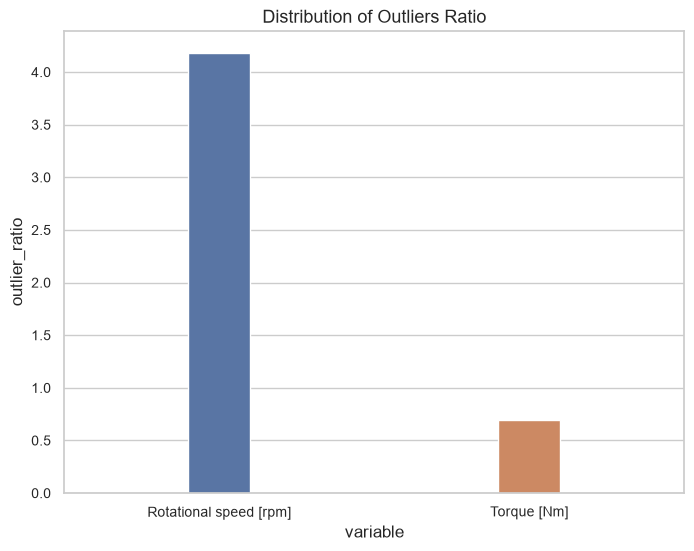

In [11]:
dict_outlier = []
# skew_col = 'Rotational speed [rpm]'

for skew_col in num_cols:
  q1 = np.percentile(df[skew_col], 25)
  q3 = np.percentile(df[skew_col], 75)

  # iqr
  iqr = q3 - q1

  # lower bound, upper bound
  lower_bound = q1 - (1.5 * iqr)
  upper_bound = q3 + (1.5 * iqr)
  outlier_count = len(df[(df[skew_col]<=lower_bound) | (df[skew_col]>=upper_bound)])

  outlier_ratio = round((outlier_count / df.shape[0]) * 100, 2)
  if outlier_ratio > 0:
    temp_outlier_ratio = {'variable': skew_col, 'outlier_ratio': outlier_ratio, 'lower_bound':lower_bound,'upper_bound':upper_bound}
    dict_outlier.append(temp_outlier_ratio)

df_outlier = pd.DataFrame(dict_outlier)
print(f'\n{df_outlier}')

title = 'Distribution of Outliers Ratio'
plot_bar(df_outlier,'variable','outlier_ratio', title)


## 3.4 Analysis Outliers Value
The very small number of outliers in column 'Torque[Nm]' is detected, which are assumed not to be data errors and is generally considered as normal.

And column 'Rotational speed' which has a moderate outlier ratio of 4.18.

Outliers are kept as real operating conditions; high-rpm/low-torque points represent the power-failure regime, and tree-based models are robust to extreme values.


In [12]:
modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
n_modes = df[modes].sum(axis=1)

print(f"Failure rate: {df['Machine failure'].mean():.2%} ({df['Machine failure'].sum()} / {len(df)})")
print("Failure-mode counts:", df[modes].sum().sort_values(ascending=False).to_dict())
print("Multi-mode records:", (n_modes > 1).sum())
print("Failure with no mode flagged:", ((df['Machine failure'] == 1) & (n_modes == 0)).sum())
print("Mode flagged but no failure:", ((df['Machine failure'] == 0) & (n_modes > 0)).sum())
print("Process - Air temp (mean K):", round((df['Process temperature [K]'] - df['Air temperature [K]']).mean(), 2))

display(df.groupby('Type')['Machine failure']
          .agg(count='count', failure_rate='mean')
          .assign(share=lambda t: t['count'] / len(df)))

Failure rate: 3.39% (339 / 10000)
Failure-mode counts: {'HDF': 115, 'OSF': 98, 'PWF': 95, 'TWF': 46, 'RNF': 19}
Multi-mode records: 24
Failure with no mode flagged: 9
Mode flagged but no failure: 18
Process - Air temp (mean K): 10.0


,count,failure_rate,share
Type,,,
H,1003,0.020937,0.1003
L,6000,0.039167,0.6000
M,2997,0.027694,0.2997


# 4. Finalised Clean Data

In [13]:
# save cleand data
df = save_cleand_data(df)
print(f"Clean Data:\n {df.head(3)}")

Clean Data:
    UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0    0    0    0  


# 5. Conclusion on EDA Findings

**Data quality**
- 10,000 records, 14 columns, no missing values and no duplicates, so no imputation was needed.
- `UDI` and `Product ID` are unique per row (identifiers only) and are excluded from modelling.
- All sensor readings fall within physically plausible ranges (Air 295–305 K, Process 306–314 K, Torque 3.8–76.6 Nm, Tool wear 0–253 min).

**Distributions**
- `Rotational speed` is the only strongly skewed feature (skewness ≈ 1.99), with a long right tail up to 2,886 rpm.
- `Torque` is close to normal (skewness ≈ 0); `Tool wear` is roughly uniform from 0 to ~200 min and tapers off after that.
- `Air temperature` and `Process temperature` are multi-modal but symmetric, and they move together (process ≈ air + 10 K).

**Outliers**
- IQR flags 4.18% of `Rotational speed` and 0.69% of `Torque` values.
- These are treated as real operating conditions, not errors. High rpm with low torque is the power-failure (PWF) regime, so removing these rows would remove failure signal.
- Decision: keep the raw values. Tree-based models are robust to extreme values, so no capping is applied.

**Target**
- Only 3.39% of machines fail (339 / 10,000), a severe class imbalance. Accuracy would be misleading, so PR-AUC and recall are used, with a stratified split.
- Failure-mode counts: HDF 115, OSF 98, PWF 95, TWF 46, RNF 19.
- Label quirks to handle in modelling:
  - 24 records have more than one failure mode (multi-label).
  - 9 failures have no mode flagged.
  - 18 records have a mode flagged but `Machine failure = 0` (mostly RNF, which is random by design).

**Machine type**
- The mix is L 60%, M 30%, H 10%.
- Failure rate rises from H (2.1%) to M (2.8%) to L (3.9%), so lower-quality variants fail more often.

**Implications for modelling**
- Use gradient-boosted trees with class weighting, and tune the decision threshold to the business recall target.
- Candidate engineered features, based on how the failure modes are defined:
  - power = torque × rpm × 2π/60 (PWF)
  - temp_diff = process − air (HDF)
  - strain = tool wear × torque (OSF)